# Image Segmentation on Weizmann

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim, peak_signal_noise_ratio as psnr
import warnings
warnings.filterwarnings('ignore')


# Image Preprocessing

In [2]:
def red_blue_to_binary(gt_img):
    gt_hsv = cv2.cvtColor(gt_img, cv2.COLOR_BGR2HSV)

    # --- Red detection (two ranges) ---
    lower_red1 = np.array([0, 100, 80])
    upper_red1 = np.array([10, 255, 255])
    lower_red2 = np.array([160, 100, 80])
    upper_red2 = np.array([180, 255, 255])
    mask_red1 = cv2.inRange(gt_hsv, lower_red1, upper_red1)
    mask_red2 = cv2.inRange(gt_hsv, lower_red2, upper_red2)
    mask_red = cv2.bitwise_or(mask_red1, mask_red2)

    # --- Blue detection ---
    lower_blue = np.array([90, 80, 50])
    upper_blue = np.array([140, 255, 255])
    mask_blue = cv2.inRange(gt_hsv, lower_blue, upper_blue)

    # Combine red + blue masks
    mask = cv2.bitwise_or(mask_red, mask_blue)

    return (mask > 0).astype(np.uint8) * 255


# Algorithm

## Kapur

In [3]:
def shannon_entropy(p):
    """
    Compute the Shannon entropy of a probability distribution.

    Parameters:
    -----------
    p : array-like
        Probability distribution (should sum to 1).

    Returns:
    --------
    H : float
        Shannon entropy (in nats).
    """
    p = np.asarray(p, dtype=np.float64)
    p = p[p > 0]  # remove zero probabilities to avoid log(0)
    H = -np.sum(p * np.log(p))
    return H

In [4]:
# ---------- 1. Kapur's entropy thresholding ----------
def kapur_threshold(img_gray):
    hist, bins = np.histogram(img_gray.ravel(), 256, [0, 256])
    hist = hist.astype(np.float32)
    hist /= hist.sum()  # normalize to probability
    cdf = np.cumsum(hist)

    best_thresh = 0
    max_entropy = -1

    for t in range(1, 255):
        # Class probabilities
        w0, w1 = cdf[t], 1 - cdf[t]
        if w0 == 0 or w1 == 0:
            continue
        # Class entropies
        h0 = hist[:t+1] / w0
        h1 = hist[t+1:] / w1
        h0 = h0[h0 > 0]
        h1 = h1[h1 > 0]
        ent = shannon_entropy(h0)+shannon_entropy(h1)
        if ent > max_entropy:
            max_entropy = ent
            best_thresh = t
    segmented = (img_gray <= best_thresh).astype(np.uint8) * 255
    return best_thresh ,segmented


## Renyi

In [5]:
def renyi_entropy(p, alpha=0.8, base=np.e):
    """
    Compute the Rényi entropy of order α for a probability distribution.

    Parameters:
    -----------
    p : array-like
        Probability distribution (should sum to 1).
    alpha : float
        Rényi entropy order parameter (alpha ≠ 1).
    base : float, optional
        Logarithm base. Use np.e for nats, 2 for bits, or 10 for bans.

    Returns:
    --------
    H : float
        Rényi entropy.
    """
    if alpha == 1:
        # Limit case → Shannon entropy
        return shannon_entropy(p)

    p = np.asarray(p, dtype=np.float64)
    p = p[p > 0]
    H = (1 / (1 - alpha)) * np.log(np.sum(p ** alpha)) / np.log(base)
    return H

In [6]:
def renyi_threshold(img_gray):
    hist, bins = np.histogram(img_gray.ravel(), 256, [0, 256])
    hist = hist.astype(np.float32)
    hist /= hist.sum()  # normalize to probability
    cdf = np.cumsum(hist)

    best_thresh = 0
    max_entropy = -1

    for t in range(1, 255):
        # Class probabilities
        w0, w1 = cdf[t], 1 - cdf[t]
        if w0 == 0 or w1 == 0:
            continue
        # Class entropies
        h0 = hist[:t+1] / w0
        h1 = hist[t+1:] / w1
        h0 = h0[h0 > 0]
        h1 = h1[h1 > 0]
        ent = renyi_entropy(h0)+renyi_entropy(h1)
        if ent > max_entropy:
            max_entropy = ent
            best_thresh = t
    segmented = (img_gray <=  best_thresh).astype(np.uint8) * 255
    return best_thresh,segmented

## Tsallis

In [7]:
def tsallis_entropy(p, q=0.5):
    """
    Compute the Tsallis entropy of order q for a probability distribution.

    Parameters:
    -----------
    p : array-like
        Probability distribution (should sum to 1).
    q : float
        Tsallis entropy order parameter (q ≠ 1).

    Returns:
    --------
    H : float
        Tsallis entropy.
    """
    p = np.asarray(p, dtype=np.float64)
    p = p[p > 0]  # remove zeros
    if q == 1:
        # Limit case → Shannon entropy
        return -np.sum(p * np.log(p))
    H = (1 - np.sum(p ** q)) / (q - 1)
    return H

In [8]:
def tsallis_threshold(img_gray):
    hist, bins = np.histogram(img_gray.ravel(), 256, [0, 256])
    hist = hist.astype(np.float32)
    hist /= hist.sum()  # normalize to probability
    cdf = np.cumsum(hist)

    best_thresh = 0
    max_entropy = -1

    for t in range(1, 255):
        # Class probabilities
        w0, w1 = cdf[t], 1 - cdf[t]
        if w0 == 0 or w1 == 0:
            continue
        # Class entropies
        h0 = hist[:t+1] / w0
        h1 = hist[t+1:] / w1
        h0 = h0[h0 > 0]
        h1 = h1[h1 > 0]
        s0=tsallis_entropy(h0)
        s1=tsallis_entropy(h1)
        ent = s0+s1+(1-0.5)*s0*s1
        if ent > max_entropy:
            max_entropy = ent
            best_thresh = t
    segmented = (img_gray <=  best_thresh).astype(np.uint8) * 255
    return best_thresh,segmented

## CRE

In [9]:
# ---------- Cumulative Residual Entropy (CRE) ----------
def cre_entropy(hist):
    """Compute Cumulative Residual Entropy for a normalized histogram."""
    F = np.cumsum(hist)
    R = 1-F
    H = shannon_entropy(R)
    return H,R

def joint_cre_independent(hist_x, hist_y):
    """Compute joint CRE for two independent discrete variables."""
    cre_x, R_x = cre_entropy(hist_x)
    cre_y, R_y = cre_entropy(hist_y)

    sum_Rx = np.sum(R_x)
    sum_Ry = np.sum(R_y)

    joint_cre = cre_x * sum_Ry + cre_y * sum_Rx
    return joint_cre

In [10]:
def cre_threshold(img_gray):
    hist, bins = np.histogram(img_gray.ravel(), 256, [0, 256])
    hist = hist.astype(np.float32)
    hist /= hist.sum()  # normalize to probability
    cdf = np.cumsum(hist)

    best_thresh = 0
    max_entropy = -1

    for t in range(1, 255):
        # Class probabilities
        w0, w1 = cdf[t], 1 - cdf[t]
        if w0 == 0 or w1 == 0:
            continue
        # Class entropies
        h0 = hist[:t+1] / w0
        h1 = hist[t+1:] / w1
        h0 = h0[h0 > 0]
        h1 = h1[h1 > 0]
        ent =cre_entropy(h0)[0]+cre_entropy(h1)[0]
        if ent > max_entropy:
            max_entropy = ent
            best_thresh = t
    segmented = (img_gray <=  best_thresh).astype(np.uint8) * 255
    return best_thresh,segmented

## NCRE

In [11]:
def ncre_threshold(img_gray):
    hist, bins = np.histogram(img_gray.ravel(), 256, [0, 256])
    hist = hist.astype(np.float32)
    hist /= hist.sum()  # normalize to probability
    cdf = np.cumsum(hist)

    best_thresh = 0
    max_entropy = -1

    for t in range(1, 255):
        # Class probabilities
        w0, w1 = cdf[t], 1 - cdf[t]
        if w0 == 0 or w1 == 0:
            continue
        # Class entropies
        h0 = hist[:t+1] / w0
        h1 = hist[t+1:] / w1
        h0 = h0[h0 > 0]
        h1 = h1[h1 > 0]
        ent=joint_cre_independent(h0,h1)
        if ent > max_entropy:
            max_entropy = ent
            best_thresh = t
    segmented = (img_gray <=  best_thresh).astype(np.uint8) * 255
    return best_thresh,segmented

## Masi

In [12]:
def masi_entropy(probabilities, r=1.2):
    """
    Compute Masi entropy for a given probability distribution.

    Parameters
    ----------
    probabilities : array-like
        Normalized probability values (sum = 1)
    r : float
        Masi entropy parameter (>0, !=1)

    Returns
    -------
    float
        Masi entropy value
    """
    p = np.array(probabilities, dtype=np.float64)
    p = p[p > 0]  # avoid log(0)
    s = np.sum(p * np.log(p))
    if (1-(1-r)*s)<=0:
        return 0
    H = (1 / (1 - r)) * np.log(1 - (1 - r) * s)
    return H

In [13]:
def masi_threshold(img_gray):
    hist, _ = np.histogram(img_gray.ravel(), 256, [0, 256])
    hist = hist.astype(np.float32)
    hist /= hist.sum()  # normalize to probability
    cdf = np.cumsum(hist)

    best_thresh = 0
    max_entropy = -np.inf

    for t in range(1, 255):
        w0, w1 = cdf[t], 1 - cdf[t]
        if w0 <= 0 or w1 <= 0:
            continue
        h0 = hist[:t+1] / w0
        h1 = hist[t+1:] / w1
        ent = masi_entropy(h0) + masi_entropy(h1)
        if ent > max_entropy:
            max_entropy = ent
            best_thresh = t
    segmented = (img_gray <=  best_thresh).astype(np.uint8) * 255
    return best_thresh,segmented

## GCRTE

In [14]:
import torch
import numpy as np
from skimage import io, img_as_ubyte
from scipy.optimize import differential_evolution

# =========================================================
# === GCRE Functions (your definitions) ====================
# =========================================================

def discrete_survival_torch(p):
    F = torch.cumsum(p, dim=0)
    R = 1 - F
    return R

def discrete_gcrte_torch(p, alpha, beta):
    # Ensure alpha, beta are tensors (handle numpy floats)
    alpha = torch.as_tensor(alpha, dtype=torch.float32, device=p.device)
    beta  = torch.as_tensor(beta, dtype=torch.float32, device=p.device)

    F = discrete_survival_torch(p)
    F = F[F > 0]
    if torch.abs(alpha - beta) > 1e-6:
        gcrte = (beta / (beta - alpha)) * torch.sum(F**alpha - F**beta)
    else:
        gcrte = -alpha * torch.sum(F**alpha * torch.log(F))
    return gcrte


def expected_value_alpha_discrete_torch(p, alpha):
    # Ensure alpha, beta are tensors (handle numpy floats)
    alpha = torch.as_tensor(alpha, dtype=torch.float32, device=p.device)
    F= discrete_survival_torch(p)
    #p = p / torch.sum(p)
    #F = torch.cumsum(p, dim=0)
    #E_alpha = torch.sum(alpha * x * p * (1 - F)**(alpha - 1))
    E_alpha = torch.sum(F**alpha)
    return E_alpha

def joint_discrete_gcrte_torch(px, py, alpha, beta):
  # Ensure alpha, beta are tensors (handle numpy floats)
    alpha = torch.as_tensor(alpha, dtype=torch.float32, device=px.device)
    beta  = torch.as_tensor(beta, dtype=torch.float32, device=px.device)

    #x_vals = torch.arange(len(px), dtype=torch.float32, device=px.device)
    #y_vals = torch.arange(len(py), dtype=torch.float32, device=py.device)
    Ex_alpha = expected_value_alpha_discrete_torch(px, alpha)
    Ey_alpha = expected_value_alpha_discrete_torch(py, alpha)
    Exy = discrete_gcrte_torch(px, alpha, beta)
    Eyy = discrete_gcrte_torch(py, alpha, beta)
    joint_entropy = Ey_alpha * Exy + Ex_alpha * Eyy + ((alpha - beta) / beta) * Exy * Eyy
    return joint_entropy


# =========================================================
# === Segmentation + Optimization Code ====================
# =========================================================

def torch_histogram(img, nbins=256):
    """Return normalized histogram as a torch tensor."""
    hist = torch.histc(img.float(), bins=nbins, min=0, max=255)
    return hist / torch.sum(hist)

def gcrte_threshold(hist, alpha, beta):
    """Find threshold t that maximizes sum of background+foreground GCRE."""
    device = hist.device
    best_t, best_score = 0, -1e9
    for t in range(1, len(hist) - 1):
        p1 = hist[:t]
        p2 = hist[t:]
        if torch.sum(p1) < 1e-8 or torch.sum(p2) < 1e-8:
            continue
        p1 = p1 / torch.sum(p1)
        p2 = p2 / torch.sum(p2)
        score = joint_discrete_gcrte_torch(p1, p2, alpha, beta)
        if score > best_score:
            best_score = score
            best_t = t
    return best_t, best_score

def iou_score(gt, seg):
    """Intersection over Union."""
    gt = gt.bool()
    seg = seg.bool()
    inter = torch.logical_and(gt, seg).sum().float()
    union = torch.logical_or(gt, seg).sum().float()
    return (inter / (union + 1e-8)).item()

def objective_alpha_beta(x, img_t, gt_t):
    alpha = torch.tensor(x[0], dtype=torch.float32, device=img_t.device)
    beta  = torch.tensor(x[1], dtype=torch.float32, device=img_t.device)
    hist = torch_histogram(img_t)
    t_opt, _ = gcrte_threshold(hist, alpha, beta)
    seg = (img_t <= t_opt).float()
    return -iou_score(gt_t, seg)


def optimize_gcrte_parameters(image, ground_truth, bounds=((0.01,2.0),(0.01,2.0)), pop=15, iters=80):
    """Find α, β, and t maximizing IoU."""
    img_t = torch.tensor(image, dtype=torch.float32)
    gt_t = torch.tensor(ground_truth, dtype=torch.float32)
    res = differential_evolution(lambda x: objective_alpha_beta(x, img_t, gt_t),
                                 bounds=bounds, maxiter=iters, popsize=pop, seed=42)
    alpha_opt, beta_opt = res.x
    hist = torch_histogram(img_t)
    t_opt, _ = gcrte_threshold(hist, alpha_opt, beta_opt)
    final_iou = iou_score(gt_t, (img_t <= t_opt).float())
    return {'alpha': alpha_opt, 'beta': beta_opt, 't': int(t_opt), 'IoU': final_iou}

# Evaluation Metric

In [15]:
# ---------- 2. Evaluation metrics ----------

def misclassification_error(segmented, ground_truth):
    """ME = misclassified pixels / total pixels"""
    return np.sum(segmented != ground_truth) / segmented.size

def feature_similarity_index(img1, img2):
    """Simple FSIM approximation using phase congruency & gradient magnitude"""
    img1 = img1.astype(np.float32)
    img2 = img2.astype(np.float32)
    # Sobel gradients
    g1x = cv2.Sobel(img1, cv2.CV_32F, 1, 0)
    g1y = cv2.Sobel(img1, cv2.CV_32F, 0, 1)
    g2x = cv2.Sobel(img2, cv2.CV_32F, 1, 0)
    g2y = cv2.Sobel(img2, cv2.CV_32F, 0, 1)
    gm1 = np.sqrt(g1x**2 + g1y**2)
    gm2 = np.sqrt(g2x**2 + g2y**2)

    T1, T2 = 0.85, 160  # constants from FSIM paper
    pc_sim = (2 * gm1 * gm2 + T1) / (gm1**2 + gm2**2 + T1)
    gm_sim = (2 * np.minimum(gm1, gm2) + T2) / (gm1 + gm2 + T2)
    fsim_map = pc_sim * gm_sim
    return np.mean(fsim_map)


In [16]:
def compute_ssim(img1, img2, window_size=11, sigma=1.5):
    """
    Compute SSIM between two grayscale images (manual implementation).
    """
    # Convert to float64 for accuracy
    img1 = img1.astype(np.float64)
    img2 = img2.astype(np.float64)

    # Constants for stability
    L = 255  # dynamic range
    C1 = (0.01 * L) ** 2
    C2 = (0.03 * L) ** 2

    # Create Gaussian window
    kernel = cv2.getGaussianKernel(window_size, sigma)
    window = kernel @ kernel.T

    # Compute local means
    mu1 = cv2.filter2D(img1, -1, window)
    mu2 = cv2.filter2D(img2, -1, window)

    # Compute variances and covariance
    mu1_sq, mu2_sq, mu1_mu2 = mu1**2, mu2**2, mu1 * mu2
    sigma1_sq = cv2.filter2D(img1**2, -1, window) - mu1_sq
    sigma2_sq = cv2.filter2D(img2**2, -1, window) - mu2_sq
    sigma12 = cv2.filter2D(img1 * img2, -1, window) - mu1_mu2

    # Compute SSIM map
    numerator = (2 * mu1_mu2 + C1) * (2 * sigma12 + C2)
    denominator = (mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2)
    ssim_map = numerator / denominator

    # Return mean SSIM
    return np.mean(ssim_map)

# Result

## Img 1

In [17]:
# ---------- 3. Load images ----------
original = cv2.imread('image/Weizmann/original/photo-026.png', cv2.IMREAD_GRAYSCALE)
gt_color = cv2.imread('image/Weizmann/groundtruth_color/photo-026.png')  # same file but color

# Convert GT to binary mask (white object, black background)
gt_binary = red_blue_to_binary(gt_color)

result = optimize_gcrte_parameters(original, gt_binary,bounds=((0.1,1.0),(0.1,1.0)), pop=15, iters=80)
thresh_val11 = result['t']
segmented11 = (original <= thresh_val11).astype(np.uint8) * 255

thresh_val1,segmented1=kapur_threshold(original)
thresh_val2,segmented2=cre_threshold(original)
thresh_val3,segmented3=renyi_threshold(original)
thresh_val4,segmented4=tsallis_threshold(original)

thresh_val6,segmented6=masi_threshold(original)

thresh_val10,segmented10=ncre_threshold(original)


threshold=[]
segmented_img=[]
for i in [1,2,3,4,6,10,11]:
    exec(f"threshold.append(thresh_val{i})")
    exec(f"segmented_img.append(segmented{i})")

def compute_metrics(segmented,gt_binary):
    me_val=round(misclassification_error(segmented,gt_binary),4)
    psnr_val=round(psnr(segmented,gt_binary),4)
    ssim_val=round(compute_ssim(segmented,gt_binary),4)
    fsim_val=round(feature_similarity_index(segmented,gt_binary),4)
    return me_val,psnr_val,ssim_val,fsim_val


method_names = ['Kapur', 'CRE', 'Renyi', 'Tsallis',  'Masi','NCRE','GCRTE']
metrics_data = []

for i in range(len(segmented_img)):
    me, psnr_val, ssim_val, fsim_val = compute_metrics(segmented_img[i], gt_binary)
    metrics_data.append([method_names[i], me, psnr_val, ssim_val, fsim_val])

metrics_df1 = pd.DataFrame(metrics_data, columns=['Method', 'Misclassification Error', 'PSNR', 'SSIM', 'FSIM'])
metrics_df1=metrics_df1.T

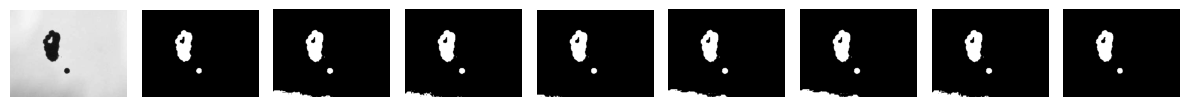

In [18]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 9, 1)
plt.imshow(original, cmap='gray')
#plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 9, 2)
plt.imshow(gt_binary, cmap='gray')
#plt.title('Ground Truth')
plt.axis('off')

plt.subplot(1, 9, 3)
plt.imshow(segmented1, cmap='gray')
#plt.title(f' Kapur (T={thresh_val1})')
plt.axis('off')



plt.subplot(1, 9, 4)
plt.imshow(segmented3, cmap='gray')
#plt.title(f' Renyi (T={thresh_val3})')
plt.axis('off')

plt.subplot(1, 9, 5)
plt.imshow(segmented4, cmap='gray')
#plt.title(f' Tsalli (T={thresh_val4})')
plt.axis('off')


plt.subplot(1, 9, 6)
plt.imshow(segmented6, cmap='gray')
#plt.title(f' Masi (T={thresh_val6})')
plt.axis('off')



plt.subplot(1, 9, 7)
plt.imshow(segmented2, cmap='gray')
#plt.title(f' CRE (T={thresh_val2})')
plt.axis('off')

plt.subplot(1, 9,8)
plt.imshow(segmented10, cmap='gray')
#plt.title(f' CRE2 (T={thresh_val10})')
plt.axis('off')

plt.subplot(1, 9,9)
plt.imshow(segmented11, cmap='gray')
#plt.title(f' GCRTE (T,α,β={thresh_val11},{result['alpha']:.2f},{result['beta']:.2f})')
plt.axis('off')

plt.tight_layout()
plt.show()

In [19]:
display(metrics_df1)

,0,1,2,3,4,5,6
Method,Kapur,CRE,Renyi,Tsallis,Masi,NCRE,GCRTE
Misclassification Error,0.02,0.0244,0.0129,0.0047,0.0244,0.0167,0.0018
PSNR,16.9994,16.134,18.9028,23.2415,16.134,17.7815,27.5012
SSIM,0.9513,0.9435,0.9598,0.9744,0.9435,0.955,0.9869
FSIM,0.9866,0.9856,0.9875,0.9913,0.9856,0.9866,0.9951


## Img 2

In [20]:
# ---------- 3. Load images ----------
original = cv2.imread('image/Weizmann/original/_mg_5707.png', cv2.IMREAD_GRAYSCALE)
gt_color = cv2.imread('image/Weizmann/groundtruth_color/_mg_5707.png')  # same file but color

# Convert GT to binary mask (white object, black background)
gt_binary = red_blue_to_binary(gt_color)

In [21]:
result = optimize_gcrte_parameters(original, gt_binary,bounds=((0.01,1.2),(0.01,1.2)), pop=15, iters=80)
thresh_val11 = result['t']
segmented11 = (original <= thresh_val11).astype(np.uint8) * 255

thresh_val1,segmented1=kapur_threshold(original)
thresh_val2,segmented2=cre_threshold(original)
thresh_val3,segmented3=renyi_threshold(original)
thresh_val4,segmented4=tsallis_threshold(original)

thresh_val6,segmented6=masi_threshold(original)

thresh_val10,segmented10=ncre_threshold(original)


threshold=[]
segmented_img=[]
for i in [1,2,3,4,6,10,11]:
    exec(f"threshold.append(thresh_val{i})")
    exec(f"segmented_img.append(segmented{i})")

def compute_metrics(segmented,gt_binary):
    me_val=round(misclassification_error(segmented,gt_binary),4)
    psnr_val=round(psnr(segmented,gt_binary),4)
    ssim_val=round(compute_ssim(segmented,gt_binary),4)
    fsim_val=round(feature_similarity_index(segmented,gt_binary),4)
    return me_val,psnr_val,ssim_val,fsim_val


method_names = ['Kapur', 'CRE', 'Renyi', 'Tsallis',  'Masi','NCRE','GCRTE']
metrics_data = []

for i in range(len(segmented_img)):
    me, psnr_val, ssim_val, fsim_val = compute_metrics(segmented_img[i], gt_binary)
    metrics_data.append([method_names[i], me, psnr_val, ssim_val, fsim_val])

metrics_df2 = pd.DataFrame(metrics_data, columns=['Method', 'Misclassification Error', 'PSNR', 'SSIM', 'FSIM'])
metrics_df2=metrics_df2.T

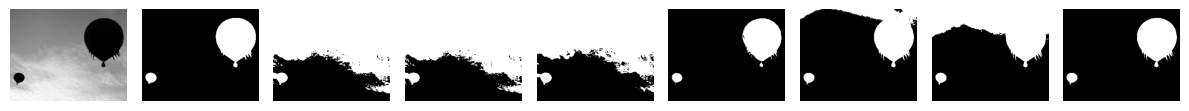

In [22]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 9, 1)
plt.imshow(original, cmap='gray')
#plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 9, 2)
plt.imshow(gt_binary, cmap='gray')
#plt.title('Ground Truth')
plt.axis('off')

plt.subplot(1, 9, 3)
plt.imshow(segmented1, cmap='gray')
#plt.title(f' Kapur (T={thresh_val1})')
plt.axis('off')



plt.subplot(1, 9, 4)
plt.imshow(segmented3, cmap='gray')
#plt.title(f' Renyi (T={thresh_val3})')
plt.axis('off')

plt.subplot(1, 9, 5)
plt.imshow(segmented4, cmap='gray')
#plt.title(f' Tsalli (T={thresh_val4})')
plt.axis('off')


plt.subplot(1, 9, 6)
plt.imshow(segmented6, cmap='gray')
#plt.title(f' Masi (T={thresh_val6})')
plt.axis('off')



plt.subplot(1, 9, 7)
plt.imshow(segmented2, cmap='gray')
#plt.title(f' CRE (T={thresh_val2})')
plt.axis('off')

plt.subplot(1, 9,8)
plt.imshow(segmented10, cmap='gray')
#plt.title(f' CRE2 (T={thresh_val10})')
plt.axis('off')

plt.subplot(1, 9,9)
plt.imshow(segmented11, cmap='gray')
#plt.title(f' GCRTE (T,α,β={thresh_val11},{result['alpha']:.2f},{result['beta']:.2f})')
plt.axis('off')

plt.tight_layout()
plt.show()

In [23]:
display(metrics_df2)

,0,1,2,3,4,5,6
Method,Kapur,CRE,Renyi,Tsallis,Masi,NCRE,GCRTE
Misclassification Error,0.4873,0.0709,0.4873,0.4489,0.0105,0.2035,0.0034
PSNR,3.1221,11.4907,3.1221,3.4781,19.7963,6.914,24.7346
SSIM,0.4241,0.8903,0.4241,0.4691,0.9419,0.7622,0.9752
FSIM,0.9329,0.9761,0.9329,0.9291,0.9763,0.9788,0.9901


## Img 3

In [24]:
# ---------- 3. Load images ----------
original = cv2.imread('image/Weizmann/original/b9vehicles_air018_cropped.png', cv2.IMREAD_GRAYSCALE)
gt_color = cv2.imread('image/Weizmann/groundtruth_color/b9vehicles_air018_cropped.png')  # same file but color

# Convert GT to binary mask (white object, black background)
gt_binary = red_blue_to_binary(gt_color)

result = optimize_gcrte_parameters(original, gt_binary,bounds=((0.01,1.2),(0.01,1.2)), pop=15, iters=80)
thresh_val11 = result['t']
segmented11 = (original <= thresh_val11).astype(np.uint8) * 255

thresh_val1,segmented1=kapur_threshold(original)
thresh_val2,segmented2=cre_threshold(original)
thresh_val3,segmented3=renyi_threshold(original)
thresh_val4,segmented4=tsallis_threshold(original)

thresh_val6,segmented6=masi_threshold(original)

thresh_val10,segmented10=ncre_threshold(original)


threshold=[]
segmented_img=[]
for i in [1,2,3,4,6,10,11]:
    exec(f"threshold.append(thresh_val{i})")
    exec(f"segmented_img.append(segmented{i})")

def compute_metrics(segmented,gt_binary):
    me_val=round(misclassification_error(segmented,gt_binary),4)
    psnr_val=round(psnr(segmented,gt_binary),4)
    ssim_val=round(compute_ssim(segmented,gt_binary),4)
    fsim_val=round(feature_similarity_index(segmented,gt_binary),4)
    return me_val,psnr_val,ssim_val,fsim_val


method_names = ['Kapur', 'CRE', 'Renyi', 'Tsallis',  'Masi','NCRE','GCRTE']
metrics_data = []

for i in range(len(segmented_img)):
    me, psnr_val, ssim_val, fsim_val = compute_metrics(segmented_img[i], gt_binary)
    metrics_data.append([method_names[i], me, psnr_val, ssim_val, fsim_val])

metrics_df3 = pd.DataFrame(metrics_data, columns=['Method', 'Misclassification Error', 'PSNR', 'SSIM', 'FSIM'])
metrics_df3=metrics_df3.T

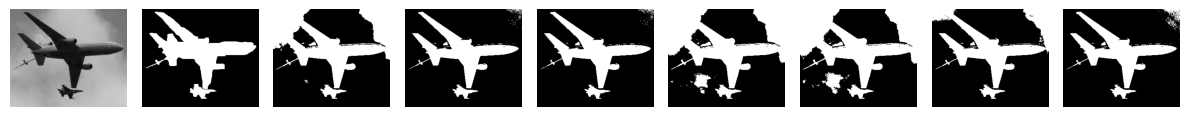

In [25]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 9, 1)
plt.imshow(original, cmap='gray')
#plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 9, 2)
plt.imshow(gt_binary, cmap='gray')
#plt.title('Ground Truth')
plt.axis('off')

plt.subplot(1, 9, 3)
plt.imshow(segmented1, cmap='gray')
#plt.title(f' Kapur (T={thresh_val1})')
plt.axis('off')



plt.subplot(1, 9, 4)
plt.imshow(segmented3, cmap='gray')
#plt.title(f' Renyi (T={thresh_val3})')
plt.axis('off')

plt.subplot(1, 9, 5)
plt.imshow(segmented4, cmap='gray')
#plt.title(f' Tsalli (T={thresh_val4})')
plt.axis('off')


plt.subplot(1, 9, 6)
plt.imshow(segmented6, cmap='gray')
#plt.title(f' Masi (T={thresh_val6})')
plt.axis('off')



plt.subplot(1, 9, 7)
plt.imshow(segmented2, cmap='gray')
#plt.title(f' CRE (T={thresh_val2})')
plt.axis('off')

plt.subplot(1, 9,8)
plt.imshow(segmented10, cmap='gray')
#plt.title(f' CRE2 (T={thresh_val10})')
plt.axis('off')

plt.subplot(1, 9,9)
plt.imshow(segmented11, cmap='gray')
#plt.title(f' GCRTE (T,α,β={thresh_val11},{result['alpha']:.2f},{result['beta']:.2f})')
plt.axis('off')

plt.tight_layout()
plt.show()

In [26]:
display(metrics_df3)

,0,1,2,3,4,5,6
Method,Kapur,CRE,Renyi,Tsallis,Masi,NCRE,GCRTE
Misclassification Error,0.1714,0.213,0.0524,0.0524,0.2055,0.1083,0.0595
PSNR,7.6594,6.7164,12.8031,12.8031,6.8722,9.6526,12.2523
SSIM,0.7029,0.6433,0.8155,0.8155,0.6545,0.7653,0.8059
FSIM,0.9284,0.9174,0.9294,0.9294,0.9206,0.9257,0.9215


## Img 4

In [27]:
# ---------- 3. Load images ----------
original = cv2.imread('image/Weizmann/original/chain98.png', cv2.IMREAD_GRAYSCALE)
gt_color = cv2.imread('image/Weizmann/groundtruth_color/chain98.png')  # same file but color

# Convert GT to binary mask (white object, black background)
gt_binary = red_blue_to_binary(gt_color)

result = optimize_gcrte_parameters(original, gt_binary,bounds=((0.01,1.2),(0.01,1.2)), pop=15, iters=80)
thresh_val11 = result['t']
segmented11 = (original <= thresh_val11).astype(np.uint8) * 255

thresh_val1,segmented1=kapur_threshold(original)
thresh_val2,segmented2=cre_threshold(original)
thresh_val3,segmented3=renyi_threshold(original)
thresh_val4,segmented4=tsallis_threshold(original)

thresh_val6,segmented6=masi_threshold(original)

thresh_val10,segmented10=ncre_threshold(original)

threshold=[]
segmented_img=[]
for i in [1,2,3,4,6,10,11]:
    exec(f"threshold.append(thresh_val{i})")
    exec(f"segmented_img.append(segmented{i})")

def compute_metrics(segmented,gt_binary):
    me_val=round(misclassification_error(segmented,gt_binary),4)
    psnr_val=round(psnr(segmented,gt_binary),4)
    ssim_val=round(compute_ssim(segmented,gt_binary),4)
    fsim_val=round(feature_similarity_index(segmented,gt_binary),4)
    return me_val,psnr_val,ssim_val,fsim_val


method_names = ['Kapur', 'CRE', 'Renyi', 'Tsallis',  'Masi','NCRE','GCRTE']
metrics_data = []

for i in range(len(segmented_img)):
    me, psnr_val, ssim_val, fsim_val = compute_metrics(segmented_img[i], gt_binary)
    metrics_data.append([method_names[i], me, psnr_val, ssim_val, fsim_val])

metrics_df4 = pd.DataFrame(metrics_data, columns=['Method', 'Misclassification Error', 'PSNR', 'SSIM', 'FSIM'])
metrics_df4=metrics_df4.T

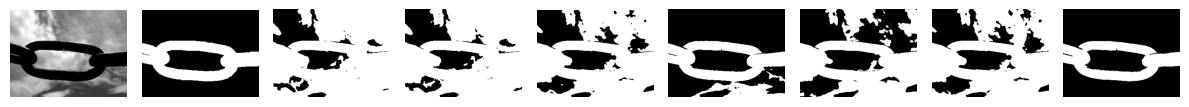

In [28]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 9, 1)
plt.imshow(original, cmap='gray')
#plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 9, 2)
plt.imshow(gt_binary, cmap='gray')
#plt.title('Ground Truth')
plt.axis('off')

plt.subplot(1, 9, 3)
plt.imshow(segmented1, cmap='gray')
#plt.title(f' Kapur (T={thresh_val1})')
plt.axis('off')



plt.subplot(1, 9, 4)
plt.imshow(segmented3, cmap='gray')
#plt.title(f' Renyi (T={thresh_val3})')
plt.axis('off')

plt.subplot(1, 9, 5)
plt.imshow(segmented4, cmap='gray')
#plt.title(f' Tsalli (T={thresh_val4})')
plt.axis('off')


plt.subplot(1, 9, 6)
plt.imshow(segmented6, cmap='gray')
#plt.title(f' Masi (T={thresh_val6})')
plt.axis('off')



plt.subplot(1, 9, 7)
plt.imshow(segmented2, cmap='gray')
#plt.title(f' CRE (T={thresh_val2})')
plt.axis('off')

plt.subplot(1, 9,8)
plt.imshow(segmented10, cmap='gray')
#plt.title(f' CRE2 (T={thresh_val10})')
plt.axis('off')

plt.subplot(1, 9,9)
plt.imshow(segmented11, cmap='gray')
#plt.title(f' GCRTE (T,α,β={thresh_val11},{result['alpha']:.2f},{result['beta']:.2f})')
plt.axis('off')

plt.tight_layout()
plt.show()

In [29]:
display(metrics_df4)

,0,1,2,3,4,5,6
Method,Kapur,CRE,Renyi,Tsallis,Masi,NCRE,GCRTE
Misclassification Error,0.5388,0.3031,0.5222,0.4571,0.0899,0.4284,0.0197
PSNR,2.6857,5.184,2.8219,3.4002,10.4633,3.6818,17.0447
SSIM,0.3375,0.5364,0.3499,0.4067,0.7953,0.427,0.8837
FSIM,0.9254,0.9118,0.9246,0.9166,0.9436,0.9103,0.9572


## Img 5

In [30]:
# ---------- 3. Load images ----------
original = cv2.imread('image/Weizmann/original/boatscn2174.png', cv2.IMREAD_GRAYSCALE)
gt_color = cv2.imread('image/Weizmann/groundtruth_color/boatscn2174.png')  # same file but color

# Convert GT to binary mask (white object, black background)
gt_binary = red_blue_to_binary(gt_color)

result = optimize_gcrte_parameters(original, gt_binary,bounds=((0.01,1.2),(0.01,1.2)), pop=15, iters=80)
thresh_val11 = result['t']
segmented11 = (original <= thresh_val11).astype(np.uint8) * 255

thresh_val1,segmented1=kapur_threshold(original)
thresh_val2,segmented2=cre_threshold(original)
thresh_val3,segmented3=renyi_threshold(original)
thresh_val4,segmented4=tsallis_threshold(original)

thresh_val6,segmented6=masi_threshold(original)

thresh_val10,segmented10=ncre_threshold(original)


threshold=[]
segmented_img=[]
for i in [1,2,3,4,6,10,11]:
    exec(f"threshold.append(thresh_val{i})")
    exec(f"segmented_img.append(segmented{i})")

def compute_metrics(segmented,gt_binary):
    me_val=round(misclassification_error(segmented,gt_binary),4)
    psnr_val=round(psnr(segmented,gt_binary),4)
    ssim_val=round(compute_ssim(segmented,gt_binary),4)
    fsim_val=round(feature_similarity_index(segmented,gt_binary),4)
    return me_val,psnr_val,ssim_val,fsim_val


method_names = ['Kapur', 'CRE', 'Renyi', 'Tsallis',  'Masi','NCRE','GCRTE']
metrics_data = []

for i in range(len(segmented_img)):
    me, psnr_val, ssim_val, fsim_val = compute_metrics(segmented_img[i], gt_binary)
    metrics_data.append([method_names[i], me, psnr_val, ssim_val, fsim_val])

metrics_df5 = pd.DataFrame(metrics_data, columns=['Method', 'Misclassification Error', 'PSNR', 'SSIM', 'FSIM'])
metrics_df5=metrics_df5.T

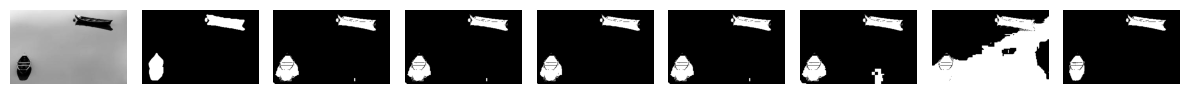

In [31]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 9, 1)
plt.imshow(original, cmap='gray')
#plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 9, 2)
plt.imshow(gt_binary, cmap='gray')
#plt.title('Ground Truth')
plt.axis('off')

plt.subplot(1, 9, 3)
plt.imshow(segmented1, cmap='gray')
#plt.title(f' Kapur (T={thresh_val1})')
plt.axis('off')



plt.subplot(1, 9, 4)
plt.imshow(segmented3, cmap='gray')
#plt.title(f' Renyi (T={thresh_val3})')
plt.axis('off')

plt.subplot(1, 9, 5)
plt.imshow(segmented4, cmap='gray')
#plt.title(f' Tsalli (T={thresh_val4})')
plt.axis('off')


plt.subplot(1, 9, 6)
plt.imshow(segmented6, cmap='gray')
#plt.title(f' Masi (T={thresh_val6})')
plt.axis('off')



plt.subplot(1, 9, 7)
plt.imshow(segmented2, cmap='gray')
#plt.title(f' CRE (T={thresh_val2})')
plt.axis('off')

plt.subplot(1, 9,8)
plt.imshow(segmented10, cmap='gray')
#plt.title(f' CRE2 (T={thresh_val10})')
plt.axis('off')

plt.subplot(1, 9,9)
plt.imshow(segmented11, cmap='gray')
#plt.title(f' GCRTE (T,α,β={thresh_val11},{result['alpha']:.2f},{result['beta']:.2f})')
plt.axis('off')

plt.tight_layout()
plt.show()

In [32]:
display(metrics_df5)

,0,1,2,3,4,5,6
Method,Kapur,CRE,Renyi,Tsallis,Masi,NCRE,GCRTE
Misclassification Error,0.0211,0.0353,0.0211,0.0191,0.0211,0.4546,0.0116
PSNR,16.7501,14.528,16.7501,17.1874,16.7501,3.4236,19.3468
SSIM,0.911,0.8875,0.911,0.9168,0.911,0.4457,0.9352
FSIM,0.9675,0.9621,0.9675,0.969,0.9675,0.9459,0.974


## Img 6

In [33]:
# ---------- 3. Load images ----------
original = cv2.imread('image/Weizmann/original/kumarnm_100_1263.png', cv2.IMREAD_GRAYSCALE)
gt_color = cv2.imread('image/Weizmann/groundtruth_color/kumarnm_100_1263.png')  # same file but color

# Convert GT to binary mask (white object, black background)
gt_binary = red_blue_to_binary(gt_color)

result = optimize_gcrte_parameters(original, gt_binary,bounds=((0.01,1.2),(0.01,1.2)), pop=15, iters=80)
thresh_val11 = result['t']
segmented11 = (original <= thresh_val11).astype(np.uint8) * 255

thresh_val1,segmented1=kapur_threshold(original)
thresh_val2,segmented2=cre_threshold(original)
thresh_val3,segmented3=renyi_threshold(original)
thresh_val4,segmented4=tsallis_threshold(original)

thresh_val6,segmented6=masi_threshold(original)

thresh_val10,segmented10=ncre_threshold(original)

threshold=[]
segmented_img=[]
for i in [1,2,3,4,6,10,11]:
    exec(f"threshold.append(thresh_val{i})")
    exec(f"segmented_img.append(segmented{i})")

def compute_metrics(segmented,gt_binary):
    me_val=round(misclassification_error(segmented,gt_binary),4)
    psnr_val=round(psnr(segmented,gt_binary),4)
    ssim_val=round(compute_ssim(segmented,gt_binary),4)
    fsim_val=round(feature_similarity_index(segmented,gt_binary),4)
    return me_val,psnr_val,ssim_val,fsim_val


method_names = ['Kapur', 'CRE', 'Renyi', 'Tsallis',  'Masi','NCRE','GCRTE']
metrics_data = []

for i in range(len(segmented_img)):
    me, psnr_val, ssim_val, fsim_val = compute_metrics(segmented_img[i], gt_binary)
    metrics_data.append([method_names[i], me, psnr_val, ssim_val, fsim_val])

metrics_df6 = pd.DataFrame(metrics_data, columns=['Method', 'Misclassification Error', 'PSNR', 'SSIM', 'FSIM'])
metrics_df6=metrics_df6.T

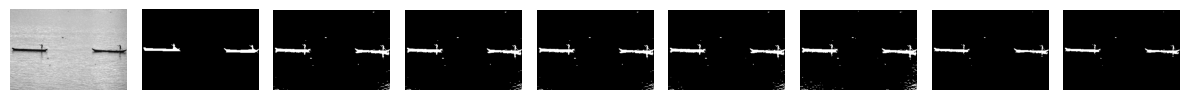

In [34]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 9, 1)
plt.imshow(original, cmap='gray')
#plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 9, 2)
plt.imshow(gt_binary, cmap='gray')
#plt.title('Ground Truth')
plt.axis('off')

plt.subplot(1, 9, 3)
plt.imshow(segmented1, cmap='gray')
#plt.title(f' Kapur (T={thresh_val1})')
plt.axis('off')



plt.subplot(1, 9, 4)
plt.imshow(segmented3, cmap='gray')
#plt.title(f' Renyi (T={thresh_val3})')
plt.axis('off')

plt.subplot(1, 9, 5)
plt.imshow(segmented4, cmap='gray')
#plt.title(f' Tsalli (T={thresh_val4})')
plt.axis('off')


plt.subplot(1, 9, 6)
plt.imshow(segmented6, cmap='gray')
#plt.title(f' Masi (T={thresh_val6})')
plt.axis('off')



plt.subplot(1, 9, 7)
plt.imshow(segmented2, cmap='gray')
#plt.title(f' CRE (T={thresh_val2})')
plt.axis('off')

plt.subplot(1, 9,8)
plt.imshow(segmented10, cmap='gray')
#plt.title(f' CRE2 (T={thresh_val10})')
plt.axis('off')

plt.subplot(1, 9,9)
plt.imshow(segmented11, cmap='gray')
#plt.title(f' GCRTE (T,α,β={thresh_val11},{result['alpha']:.2f},{result['beta']:.2f})')
plt.axis('off')

plt.tight_layout()
plt.show()

In [35]:
display(metrics_df6)

,0,1,2,3,4,5,6
Method,Kapur,CRE,Renyi,Tsallis,Masi,NCRE,GCRTE
Misclassification Error,0.0149,0.019,0.0149,0.0149,0.0155,0.01,0.0099
PSNR,18.2789,17.2158,18.2789,18.2789,18.1082,20.007,20.0563
SSIM,0.9201,0.883,0.9201,0.9201,0.9133,0.9499,0.9503
FSIM,0.97,0.9587,0.97,0.97,0.9684,0.9796,0.98


## Performance Table

In [36]:
combined_metrics_df = pd.concat([
    metrics_df1.assign(Image='Img 1').reset_index().rename(columns={'index': 'Method'}),
    metrics_df2.assign(Image='Img 2').reset_index().rename(columns={'index': 'Method'}),
    metrics_df3.assign(Image='Img 3').reset_index().rename(columns={'index': 'Method'}),
    metrics_df4.assign(Image='Img 4').reset_index().rename(columns={'index': 'Method'}),
    metrics_df5.assign(Image='Img 5').reset_index().rename(columns={'index': 'Method'}),
    metrics_df6.assign(Image='Img 6').reset_index().rename(columns={'index': 'Method'})
], ignore_index=True)



In [37]:
indexed_metrics_df = combined_metrics_df.set_index('Image')
indexed_metrics_df = indexed_metrics_df[indexed_metrics_df['Method'] != 'Method']

In [38]:
method_names = ['Kapur', 'CRE', 'Renyi', 'Tsallis',  'Masi','NCRE','GCRTE']
# Rename the columns in metrics_with_blanks
indexed_metrics_df.columns = ['Method'] + method_names
indexed_metrics_df[indexed_metrics_df['Method'] =='FSIM'] = indexed_metrics_df[indexed_metrics_df['Method'] =='FSIM'].round(4)
display(indexed_metrics_df)

,Method,Kapur,CRE,Renyi,Tsallis,Masi,NCRE,GCRTE
Image,,,,,,,,
Img 1,Misclassification Error,0.02,0.0244,0.0129,0.0047,0.0244,0.0167,0.0018
Img 1,PSNR,16.9994,16.134,18.9028,23.2415,16.134,17.7815,27.5012
Img 1,SSIM,0.9513,0.9435,0.9598,0.9744,0.9435,0.955,0.9869
Img 1,FSIM,0.9866,0.9856,0.9875,0.9913,0.9856,0.9866,0.9951
Img 2,Misclassification Error,0.4873,0.0709,0.4873,0.4489,0.0105,0.2035,0.0034
Img 2,PSNR,3.1221,11.4907,3.1221,3.4781,19.7963,6.914,24.7346
Img 2,SSIM,0.4241,0.8903,0.4241,0.4691,0.9419,0.7622,0.9752
Img 2,FSIM,0.9329,0.9761,0.9329,0.9291,0.9763,0.9788,0.9901
Img 3,Misclassification Error,0.1714,0.213,0.0524,0.0524,0.2055,0.1083,0.0595
